In [31]:
import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

np.random.seed(42)

IMG_PATH = "2026_NYCU.png"
IMG_SIZE = 80

EPOCHS = 800
BATCH_SIZE = 256
LEARNING_RATE = 0.05

NUM_FREQ = 6
HIDDEN_UNITS = 128
SNAPSHOT_EPOCHS = [100, 200, 400, 800]

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

Image shape: (80, 80, 3)
Number of pixels: 6400


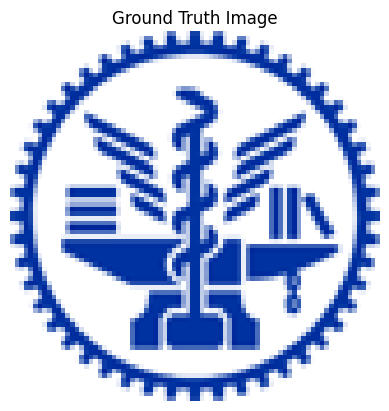

In [32]:
if not os.path.exists(IMG_PATH):
    raise FileNotFoundError(f"找不到圖片：{IMG_PATH}")

img_raw = Image.open(IMG_PATH).convert("RGBA")
background = Image.new("RGBA", img_raw.size, (255, 255, 255, 255))
img = Image.alpha_composite(background, img_raw).convert("RGB")
img = img.resize((IMG_SIZE, IMG_SIZE))

# RGB values: (0, 255) to (0, 1)
img_arr = np.asarray(img, dtype=np.float64) / 255.0

H, W, C = img_arr.shape
N = H * W

print("Image shape:", img_arr.shape)
print("Number of pixels:", N)

plt.imshow(img_arr)
plt.title("Ground Truth Image")
plt.axis("off")
plt.show()

In [33]:
# Normalize to (-1, 1)
x = np.linspace(-1.0, 1.0, W)
y = np.linspace(-1.0, 1.0, H)

xx, yy = np.meshgrid(x, y, indexing="xy")

full_coords = np.stack(
    [xx.reshape(-1), yy.reshape(-1)],
    axis=1
)

colors = img_arr.reshape(-1, 3)

print("Coordinates shape:", full_coords.shape)
print("Colors shape:", colors.shape)

Coordinates shape: (6400, 2)
Colors shape: (6400, 3)


In [34]:
indices = np.random.permutation(N)
n_train = int(0.9 * N)

train_idx = indices[:n_train]
test_idx = indices[n_train:]

X_train = full_coords[train_idx]
Y_train = colors[train_idx]

X_test = full_coords[test_idx]
Y_test = colors[test_idx]

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test :", X_test.shape)
print("Y_test :", Y_test.shape)

X_train: (5760, 2)
Y_train: (5760, 3)
X_test : (640, 2)
Y_test : (640, 3)


In [35]:
def fourier_features(x, num_freq=6):
    """
    Input:
        x: (N, 2), normalized coordinates

    Output:
        (N, 2 + 4*num_freq)

    Features include raw coordinates and sine/cosine
    features for both x and y coordinates.
    """
    freqs = (2.0 ** np.arange(num_freq)) * np.pi

    features = [x]

    for freq in freqs:
        features.append(np.sin(freq * x))
        features.append(np.cos(freq * x))

    return np.concatenate(features, axis=1)

In [36]:
class MLP:
    def __init__(self, layer_sizes, lr=0.01):
        self.lr = lr
        self.L = len(layer_sizes) - 1

        self.W = []
        self.b = []

        for i in range(self.L):
            fan_in = layer_sizes[i]
            fan_out = layer_sizes[i + 1]

            weight = (
                np.random.randn(fan_in, fan_out)
                * np.sqrt(2.0 / fan_in)
            )

            bias = np.zeros((1, fan_out))

            self.W.append(weight)
            self.b.append(bias)

    @staticmethod
    def relu(z):
        return np.maximum(0.0, z)

    @staticmethod
    def relu_grad(z):
        return (z > 0).astype(np.float64)

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500.0, 500.0)
        return 1.0 / (1.0 + np.exp(-z))

    def forward(self, X):
        self.z_cache = []
        self.a_cache = [X]

        a = X

        for i in range(self.L):
            z = a @ self.W[i] + self.b[i]

            if i < self.L - 1:
                a = self.relu(z)
            else:
                a = self.sigmoid(z)

            self.z_cache.append(z)
            self.a_cache.append(a)

        return a

    def backward(self, Y):
        """
        Backpropagation for mean squared error:

        MSE = mean((prediction - target) ** 2)

        The mean is over both samples and RGB channels.
        """
        m = Y.shape[0]
        output_dim = Y.shape[1]

        y_pred = self.a_cache[-1]

        # dMSE / dA_output
        dA = 2.0 * (y_pred - Y) / (m * output_dim)

        # Sigmoid derivative
        dZ = dA * y_pred * (1.0 - y_pred)

        grads_W = [None] * self.L
        grads_b = [None] * self.L

        for i in reversed(range(self.L)):
            A_prev = self.a_cache[i]

            grads_W[i] = A_prev.T @ dZ
            grads_b[i] = np.sum(
                dZ, axis=0, keepdims=True
            )

            if i > 0:
                dA_prev = dZ @ self.W[i].T
                dZ = (
                    dA_prev
                    * self.relu_grad(self.z_cache[i - 1])
                )

        # SGD parameter update
        for i in range(self.L):
            self.W[i] -= self.lr * grads_W[i]
            self.b[i] -= self.lr * grads_b[i]

    def predict(self, X):
        return self.forward(X)

In [37]:
def calculate_mse(model, X, Y):
    prediction = model.predict(X)
    return float(np.mean((prediction - Y) ** 2))


def calculate_rms(model, X, Y):
    return float(np.sqrt(calculate_mse(model, X, Y)))


def train_model(
    X_train,
    Y_train,
    X_test,
    Y_test,
    layer_sizes,
    lr,
    epochs,
    batch_size,
    snapshot_epochs,
    full_coords
):
    model = MLP(layer_sizes, lr=lr)

    n = X_train.shape[0]

    train_mse_history = []
    test_mse_history = []
    snapshots = {}

    for epoch in range(1, epochs + 1):

        # Shuffle training
        perm = np.random.permutation(n)
        X_shuffled = X_train[perm]
        Y_shuffled = Y_train[perm]

        for start in range(0, n, batch_size):
            end = start + batch_size

            xb = X_shuffled[start:end]
            yb = Y_shuffled[start:end]

            model.forward(xb)
            model.backward(yb)

        # Evaluate after updates
        train_mse = calculate_mse(model, X_train, Y_train)
        test_mse = calculate_mse(model, X_test, Y_test)

        train_mse_history.append(train_mse)
        test_mse_history.append(test_mse)

        # Save reconstruction
        if epoch in snapshot_epochs:
            reconstruction = model.predict(full_coords)
            snapshots[epoch] = reconstruction.copy()

        if (
            epoch == 1
            or epoch % 50 == 0
            or epoch in snapshot_epochs
        ):
            train_rms = np.sqrt(train_mse)
            test_rms = np.sqrt(test_mse)

            print(
                f"Epoch {epoch:4d}/{epochs} | "
                f"Train MSE: {train_mse:.6f} | "
                f"Test MSE: {test_mse:.6f} | "
                f"Train RMS: {train_rms:.6f} | "
                f"Test RMS: {test_rms:.6f}"
            )

    return (
        model,
        train_mse_history,
        test_mse_history,
        snapshots
    )

In [38]:
print("========== RAW COORDINATES ==========")

raw_layer_sizes = [
    2,
    HIDDEN_UNITS,
    HIDDEN_UNITS,
    HIDDEN_UNITS,
    3
]

model_raw, loss_raw, test_loss_raw, snap_raw = train_model(
    X_train=X_train,
    Y_train=Y_train,
    X_test=X_test,
    Y_test=Y_test,
    layer_sizes=raw_layer_sizes,
    lr=LEARNING_RATE,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    snapshot_epochs=SNAPSHOT_EPOCHS,
    full_coords=full_coords
)

train_rms_raw = calculate_rms(model_raw, X_train, Y_train)
test_rms_raw = calculate_rms(model_raw, X_test, Y_test)

print("\nRaw-coordinate final results")
print("Train RMS:", train_rms_raw)
print("Test RMS :", test_rms_raw)

========== RAW COORDINATES ==========
Epoch    1/800 | Train MSE: 0.108180 | Test MSE: 0.103460 | Train RMS: 0.328908 | Test RMS: 0.321653
Epoch   50/800 | Train MSE: 0.093680 | Test MSE: 0.088676 | Train RMS: 0.306071 | Test RMS: 0.297785
Epoch  100/800 | Train MSE: 0.092273 | Test MSE: 0.087865 | Train RMS: 0.303764 | Test RMS: 0.296421
Epoch  150/800 | Train MSE: 0.091370 | Test MSE: 0.087164 | Train RMS: 0.302275 | Test RMS: 0.295235
Epoch  200/800 | Train MSE: 0.090634 | Test MSE: 0.086702 | Train RMS: 0.301054 | Test RMS: 0.294452
Epoch  250/800 | Train MSE: 0.090003 | Test MSE: 0.086154 | Train RMS: 0.300004 | Test RMS: 0.293520
Epoch  300/800 | Train MSE: 0.089454 | Test MSE: 0.085710 | Train RMS: 0.299089 | Test RMS: 0.292762
Epoch  350/800 | Train MSE: 0.088973 | Test MSE: 0.085199 | Train RMS: 0.298283 | Test RMS: 0.291888
Epoch  400/800 | Train MSE: 0.088558 | Test MSE: 0.084836 | Train RMS: 0.297586 | Test RMS: 0.291265
Epoch  450/800 | Train MSE: 0.088193 | Test MSE: 0.08

In [39]:
print("========== FOURIER ENCODING ==========")

X_train_enc = fourier_features(X_train, NUM_FREQ)
X_test_enc = fourier_features(X_test, NUM_FREQ)
full_coords_enc = fourier_features(full_coords, NUM_FREQ)

enc_dim = X_train_enc.shape[1]

print("Fourier feature dimension:", enc_dim)

enc_layer_sizes = [
    enc_dim,
    HIDDEN_UNITS,
    HIDDEN_UNITS,
    HIDDEN_UNITS,
    3
]

model_enc, loss_enc, test_loss_enc, snap_enc = train_model(
    X_train=X_train_enc,
    Y_train=Y_train,
    X_test=X_test_enc,
    Y_test=Y_test,
    layer_sizes=enc_layer_sizes,
    lr=LEARNING_RATE,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    snapshot_epochs=SNAPSHOT_EPOCHS,
    full_coords=full_coords_enc
)

train_rms_enc = calculate_rms(model_enc, X_train_enc, Y_train)
test_rms_enc = calculate_rms(model_enc, X_test_enc, Y_test)

print("\nFourier-encoded final results")
print("Train RMS:", train_rms_enc)
print("Test RMS :", test_rms_enc)

========== FOURIER ENCODING ==========
Fourier feature dimension: 26
Epoch    1/800 | Train MSE: 0.116819 | Test MSE: 0.108806 | Train RMS: 0.341787 | Test RMS: 0.329857
Epoch   50/800 | Train MSE: 0.083962 | Test MSE: 0.085269 | Train RMS: 0.289762 | Test RMS: 0.292009
Epoch  100/800 | Train MSE: 0.072562 | Test MSE: 0.080226 | Train RMS: 0.269374 | Test RMS: 0.283241
Epoch  150/800 | Train MSE: 0.063295 | Test MSE: 0.076149 | Train RMS: 0.251585 | Test RMS: 0.275952
Epoch  200/800 | Train MSE: 0.055267 | Test MSE: 0.072537 | Train RMS: 0.235090 | Test RMS: 0.269327
Epoch  250/800 | Train MSE: 0.047435 | Test MSE: 0.069370 | Train RMS: 0.217796 | Test RMS: 0.263382
Epoch  300/800 | Train MSE: 0.039655 | Test MSE: 0.065417 | Train RMS: 0.199136 | Test RMS: 0.255768
Epoch  350/800 | Train MSE: 0.032605 | Test MSE: 0.061686 | Train RMS: 0.180569 | Test RMS: 0.248366
Epoch  400/800 | Train MSE: 0.026127 | Test MSE: 0.058564 | Train RMS: 0.161637 | Test RMS: 0.241999
Epoch  450/800 | Train

In [40]:
print("===== Network Architecture =====")
print("Raw     :", " -> ".join(map(str, raw_layer_sizes)),
      "(ReLU x3 hidden, Sigmoid output)")
print("Fourier :", " -> ".join(map(str, enc_layer_sizes)),
      "(ReLU x3 hidden, Sigmoid output)")
print(f"Hidden layers: 3 | Units/layer: {HIDDEN_UNITS} | "
      f"Epochs: {EPOCHS} | Batch: {BATCH_SIZE} | LR: {LEARNING_RATE}")

print("\n===== RMS Error =====")
print(f"{'Input':<10}{'Train RMS':>12}{'Test RMS':>12}")
print(f"{'Raw':<10}{train_rms_raw:>12.4f}{test_rms_raw:>12.4f}")
print(f"{'Fourier':<10}{train_rms_enc:>12.4f}{test_rms_enc:>12.4f}")

===== Network Architecture =====
Raw     : 2 -> 128 -> 128 -> 128 -> 3 (ReLU x3 hidden, Sigmoid output)
Fourier : 26 -> 128 -> 128 -> 128 -> 3 (ReLU x3 hidden, Sigmoid output)
Hidden layers: 3 | Units/layer: 128 | Epochs: 800 | Batch: 256 | LR: 0.05

===== RMS Error =====
Input        Train RMS    Test RMS
Raw             0.2936      0.2891
Fourier         0.0749      0.2077


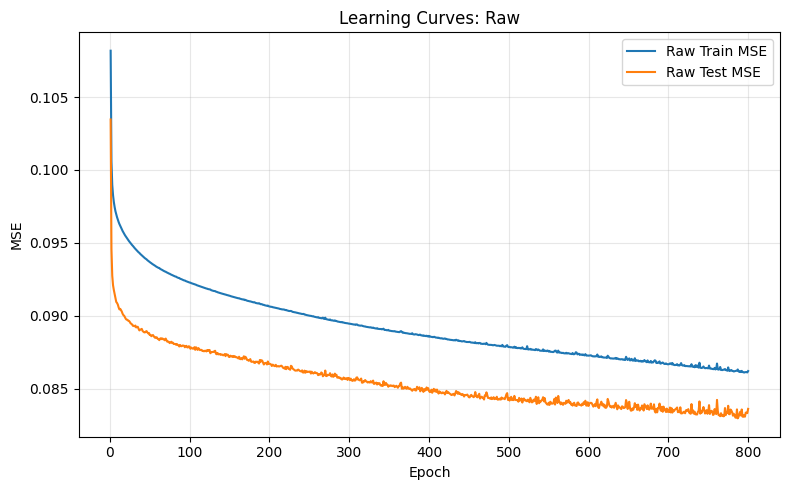

In [41]:
# --- Raw Learning Curve ---
plt.figure(figsize=(8, 5))

plt.plot(range(1, EPOCHS + 1), loss_raw, label="Raw Train MSE")
plt.plot(range(1, EPOCHS + 1), test_loss_raw, label="Raw Test MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Learning Curves: Raw")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "learning_curves_raw.png"), dpi=200)
plt.show()

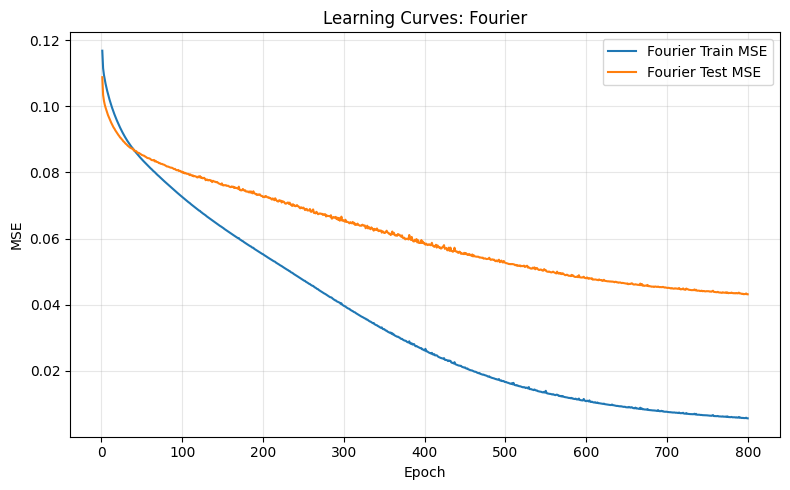

In [42]:
# --- Fourier Learning Curve ---
plt.figure(figsize=(8, 5))

plt.plot(range(1, EPOCHS + 1), loss_enc, label="Fourier Train MSE")
plt.plot(range(1, EPOCHS + 1), test_loss_enc, label="Fourier Test MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Learning Curves: Fourier")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "learning_curves_fourier.png"), dpi=200)
plt.show()

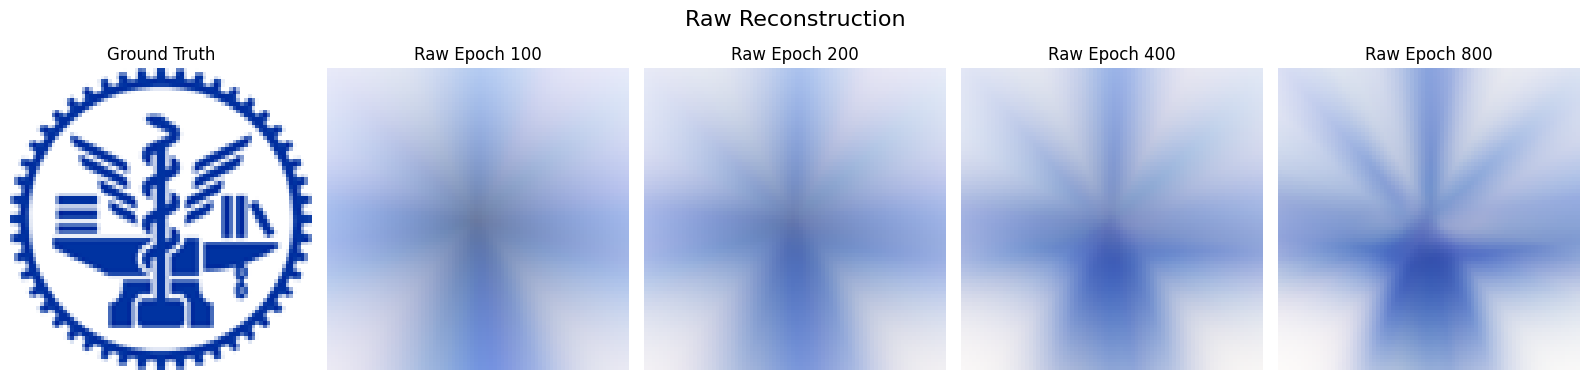

In [43]:
fig_raw, axes_raw = plt.subplots(1, len(SNAPSHOT_EPOCHS) + 1, figsize=(16, 4))

axes_raw = np.atleast_1d(axes_raw)

axes_raw[0].imshow(img_arr)
axes_raw[0].set_title("Ground Truth")
axes_raw[0].axis("off")

for j, epoch in enumerate(SNAPSHOT_EPOCHS, start=1):
    raw_img = np.clip(snap_raw[epoch].reshape(H, W, 3), 0.0, 1.0)

    axes_raw[j].imshow(raw_img)
    axes_raw[j].set_title(f"Raw Epoch {epoch}")
    axes_raw[j].axis("off")

fig_raw.suptitle("Raw Reconstruction", fontsize=16)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "raw_reconstructions.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

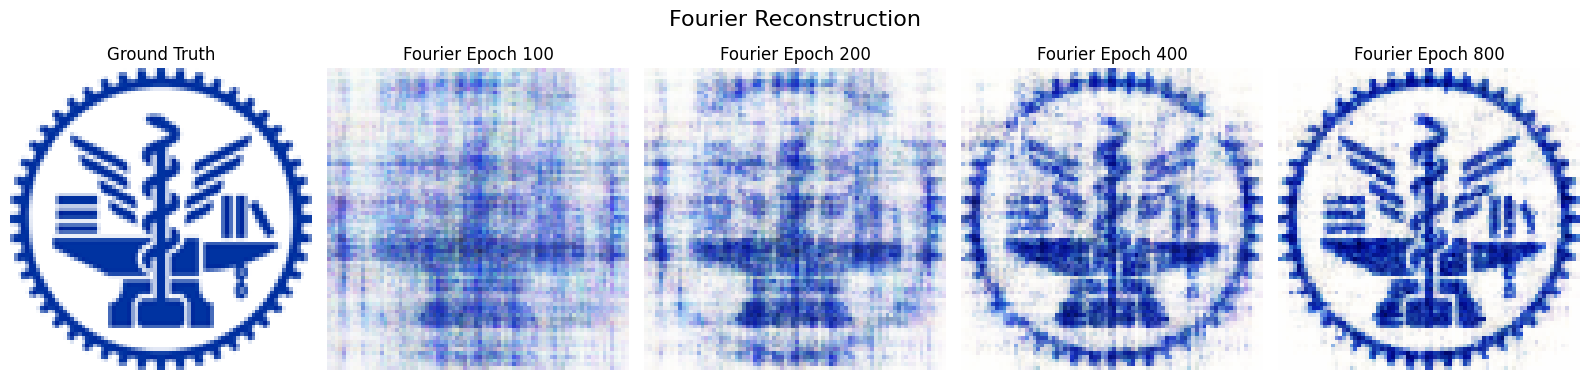

In [44]:
fig_enc, axes_enc = plt.subplots(1, len(SNAPSHOT_EPOCHS) + 1, figsize=(16, 4))

axes_enc = np.atleast_1d(axes_enc)

axes_enc[0].imshow(img_arr)
axes_enc[0].set_title("Ground Truth")
axes_enc[0].axis("off")

for j, epoch in enumerate(SNAPSHOT_EPOCHS, start=1):
    enc_img = np.clip(snap_enc[epoch].reshape(H, W, 3), 0.0, 1.0)

    axes_enc[j].imshow(enc_img)
    axes_enc[j].set_title(f"Fourier Epoch {epoch}")
    axes_enc[j].axis("off")

fig_enc.suptitle("Fourier Reconstruction", fontsize=16)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "fourier_reconstructions.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

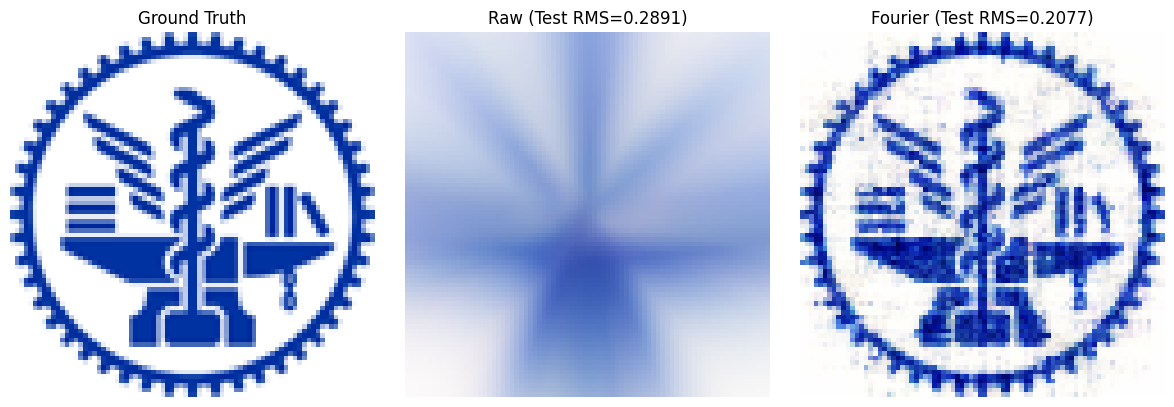

In [45]:
raw_final = np.clip(snap_raw[EPOCHS].reshape(H, W, 3), 0.0, 1.0)
enc_final = np.clip(snap_enc[EPOCHS].reshape(H, W, 3), 0.0, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_arr)
axes[0].set_title("Ground Truth")

axes[1].imshow(raw_final)
axes[1].set_title(f"Raw (Test RMS={test_rms_raw:.4f})")

axes[2].imshow(enc_final)
axes[2].set_title(f"Fourier (Test RMS={test_rms_enc:.4f})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "raw_vs_fourier.png"), dpi=200)
plt.show()